# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (TensorFlow / Keras)

| Nama | NRP |
|------|-----|
| Sulaiman Faiz Tsaqib | 5054251048 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **TensorFlow / Keras** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, tensorflow, dll).
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan tf.keras.utils.set_random_seed(42).
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, roc_auc_score

tf.keras.utils.set_random_seed(42)

In [2]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
df = pd.read_csv('Churn_Modelling.csv')
display(df.head())
print('Shape:', df.shape)
df.info()
display(df.describe())
print(df.isnull().sum())

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Shape: (10000, 14)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64


Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64


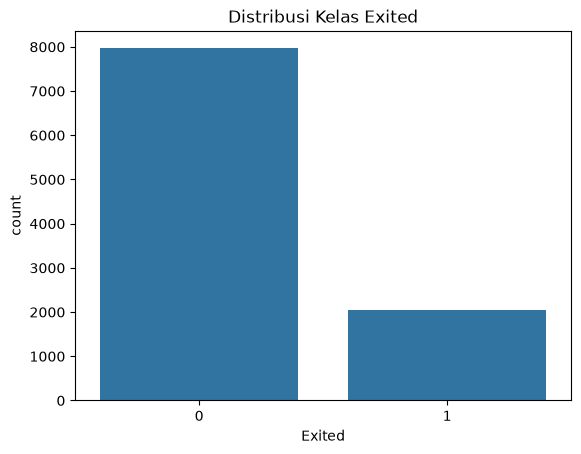

In [3]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
print(df['Exited'].value_counts(normalize=True))
sns.countplot(x='Exited', data=df)
plt.title('Distribusi Kelas Exited')
plt.show()

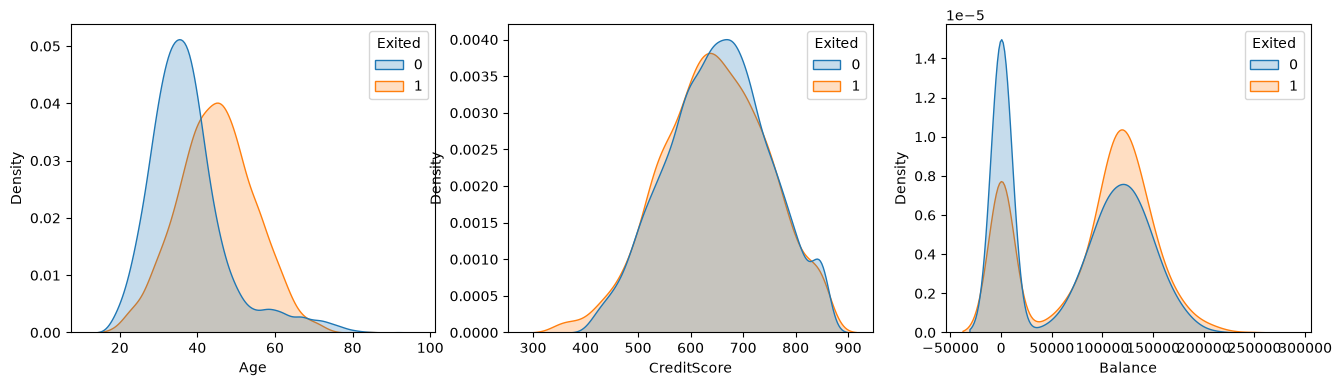

In [4]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, ['Age', 'CreditScore', 'Balance']):
    sns.kdeplot(data=df, x=col, hue='Exited', common_norm=False, fill=True, ax=a)
plt.show()

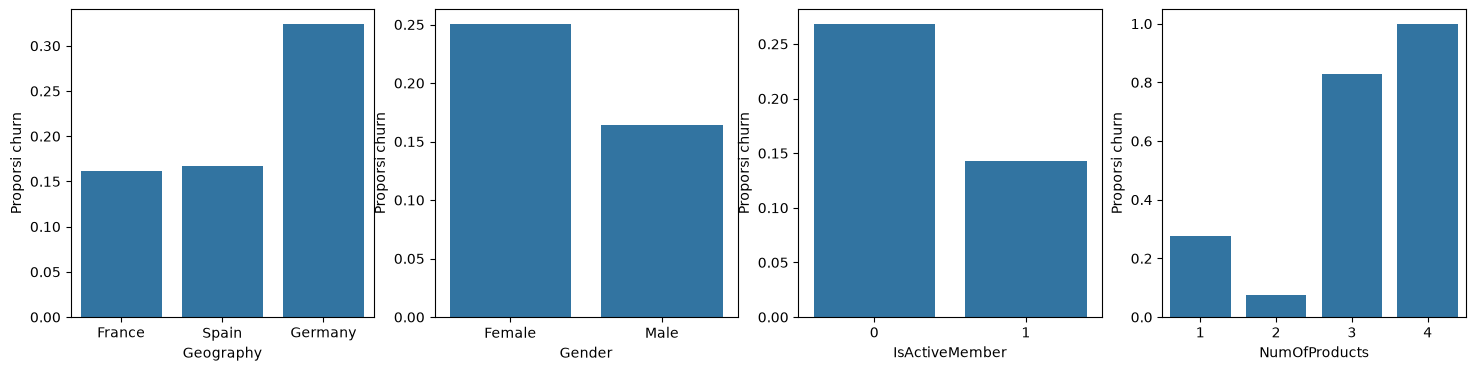

In [5]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, col in zip(ax, ['Geography', 'Gender', 'IsActiveMember', 'NumOfProducts']):
    sns.barplot(data=df, x=col, y='Exited', errorbar=None, ax=a)
    a.set_ylabel('Proporsi churn')
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

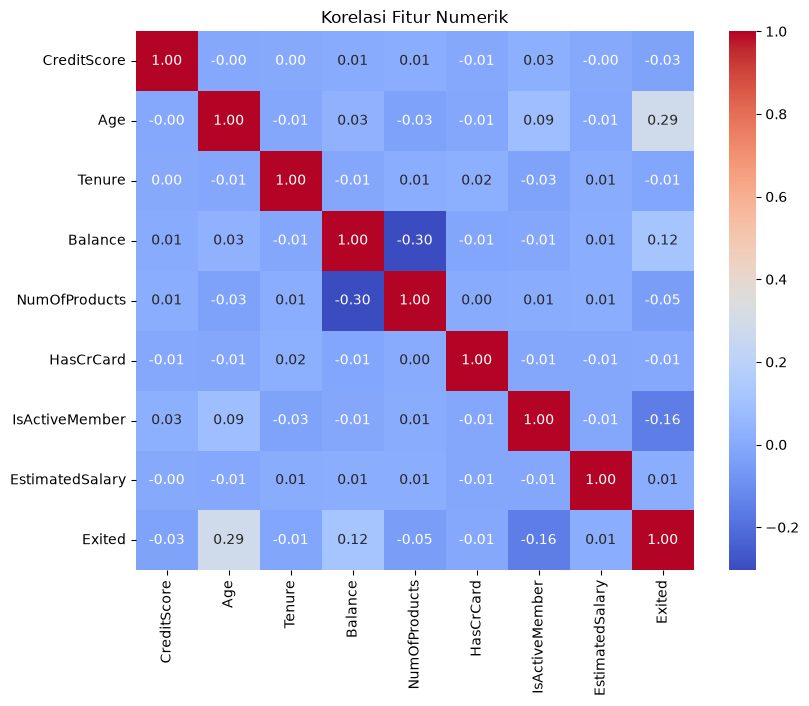

In [6]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.drop(columns=['RowNumber', 'CustomerId']).corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Korelasi Fitur Numerik')
plt.show()

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [7]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.
# RowNumber, CustomerId, dan Surname hanya identitas nasabah, tidak berhubungan dengan perilaku churn
df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

In [8]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.
X = df.drop(columns='Exited')
y = df['Exited']
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)
print(X_train.shape, X_val.shape, X_test.shape)

(7000, 10) (1500, 10) (1500, 10)


In [9]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.
num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']
ct = ColumnTransformer([
    ('cat', OneHotEncoder(drop='if_binary'), ['Geography', 'Gender']),
    ('num', StandardScaler(), num_cols)
], remainder='passthrough')  # HasCrCard dan IsActiveMember sudah 0/1

X_train = ct.fit_transform(X_train)
X_val = ct.transform(X_val)
X_test = ct.transform(X_test)
print(ct.get_feature_names_out())

['cat__Geography_France' 'cat__Geography_Germany' 'cat__Geography_Spain'
 'cat__Gender_Male' 'num__CreditScore' 'num__Age' 'num__Tenure'
 'num__Balance' 'num__NumOfProducts' 'num__EstimatedSalary'
 'remainder__HasCrCard' 'remainder__IsActiveMember']


In [10]:
# Pastikan X dan y untuk train, validation, dan test berupa numpy array bertipe float32.
# Contoh: X_train = np.asarray(X_train, dtype="float32")
X_train, X_val, X_test = [np.asarray(a, dtype='float32') for a in (X_train, X_val, X_test)]
y_train, y_val, y_test = [np.asarray(a, dtype='float32') for a in (y_train, y_val, y_test)]

# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [11]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.
logreg = LogisticRegression()
logreg.fit(X_train, y_train)
y_pred_lr = logreg.predict(X_test)
y_prob_lr = logreg.predict_proba(X_test)[:, 1]

## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer**. Karena ini klasifikasi biner, gunakan **1 neuron output dengan aktivasi Sigmoid** dan **Binary Cross-Entropy** sebagai loss function.

Contoh arsitektur: `Input → Dense(16, ReLU) → Dense(1, Sigmoid)`

In [12]:
# Definisikan arsitektur ANN sederhana menggunakan keras.Sequential.
# Gunakan keras.Input(shape=(jumlah_fitur,)) sebagai layer pertama, lalu layers.Dense untuk hidden layer dan output layer.
# Tampilkan ringkasan model beserta jumlah parameternya dengan model.summary().
model1 = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])
model1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225 (900.00 B)

 Trainable params: 225 (900.00 B)

 Non-trainable params: 0 (0.00 B)

In [13]:
# Compile model: tentukan optimizer (misalnya keras.optimizers.Adam(learning_rate=...)), loss="binary_crossentropy", dan metrics=["accuracy"].
# Latih model dengan model.fit(), gunakan validation_data=(X_val, y_val) agar loss dan accuracy validation tercatat setiap epoch.
# Simpan hasil model.fit() ke variabel history.
def compile_fit(model, epochs=50, batch_size=64, lr=1e-3, **kwargs):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss='binary_crossentropy', metrics=['accuracy'])
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epochs, batch_size=batch_size, verbose=0, **kwargs)
    print(f"train acc: {history.history['accuracy'][-1]:.4f} | val acc: {history.history['val_accuracy'][-1]:.4f}")
    return history

history1 = compile_fit(model1)

train acc: 0.8569 | val acc: 0.8613


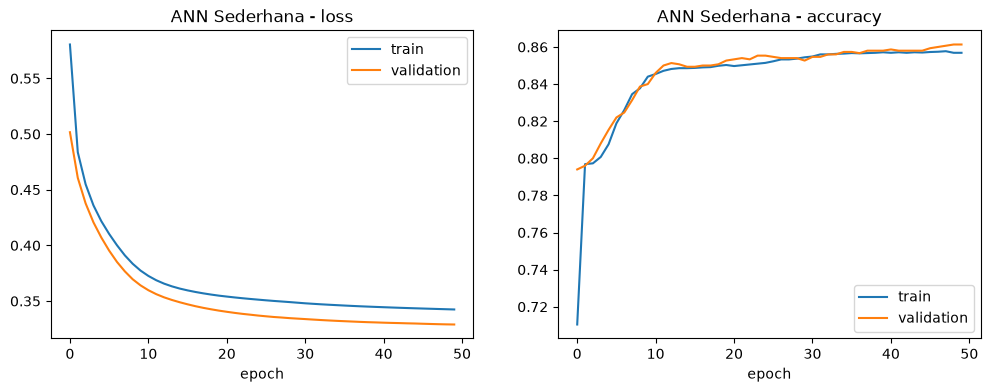

In [14]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot.
# Gunakan history.history["loss"], history.history["val_loss"], history.history["accuracy"], dan history.history["val_accuracy"].
def plot_history(history, title):
    h = history.history
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, m in zip(ax, ['loss', 'accuracy']):
        a.plot(h[m], label='train')
        a.plot(h['val_' + m], label='validation')
        a.set_title(f'{title} - {m}')
        a.set_xlabel('epoch')
        a.legend()
    plt.show()

plot_history(history1, 'ANN Sederhana')

In [15]:
# Lakukan prediksi pada test set dengan model.predict(X_test). Hasilnya berupa probabilitas kelas 1.
# Ubah menjadi label dengan threshold 0.5, lalu simpan probabilitas dan label untuk keperluan evaluasi.
def predict(model, X):
    prob = model.predict(X, verbose=0).ravel()
    return (prob >= 0.5).astype(int), prob

y_pred_1, y_prob_1 = predict(model1, X_test)

## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [16]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan layers.Dropout(rate) di antara hidden layer.
# Tampilkan ringkasan model beserta jumlah parameternya.
def build_deep(rate=0.3):
    return keras.Sequential([
        keras.Input(shape=(X_train.shape[1],)),
        layers.Dense(64, activation='relu'),
        layers.Dropout(rate),
        layers.Dense(32, activation='relu'),
        layers.Dropout(rate),
        layers.Dense(1, activation='sigmoid')
    ])

model2 = build_deep()
model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)

train acc: 0.8607 | val acc: 0.8660


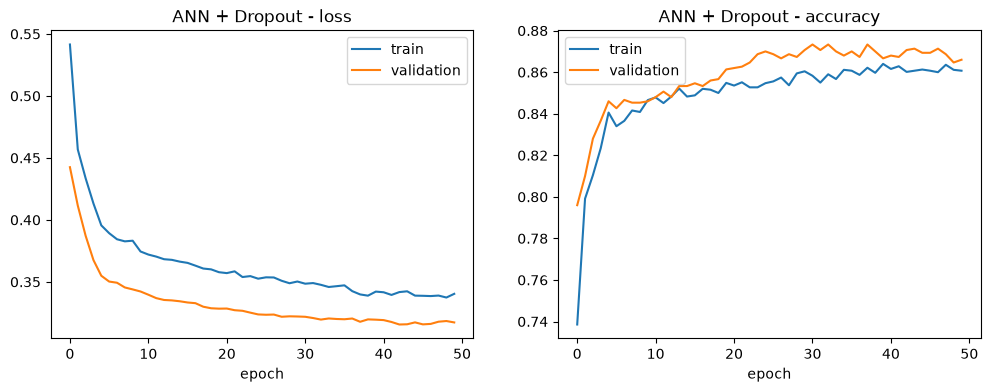

In [17]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?
history2 = compile_fit(model2)
plot_history(history2, 'ANN + Dropout')

In [18]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.
y_pred_2, y_prob_2 = predict(model2, X_test)

## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [19]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung bobot setiap kelas berdasarkan train set, misalnya dengan sklearn.utils.class_weight.compute_class_weight("balanced", ...).
# Masukkan ke model.fit() melalui parameter class_weight={0: bobot_kelas_0, 1: bobot_kelas_1}.
w = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight = {0: w[0], 1: w[1]}
print('class_weight:', class_weight)

model3 = build_deep()
history3 = compile_fit(model3, class_weight=class_weight)

class_weight: {0: np.float64(0.6279153211338356), 1: np.float64(2.4544179523141656)}


train acc: 0.7854 | val acc: 0.7867


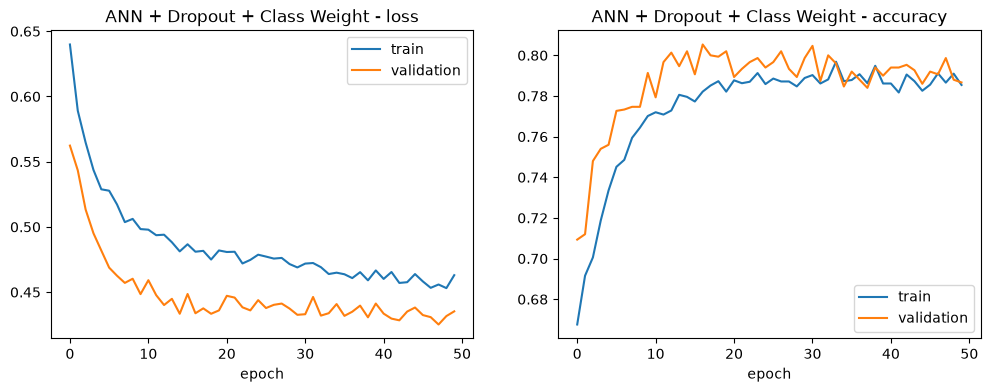

In [20]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.
plot_history(history3, 'ANN + Dropout + Class Weight')
y_pred_3, y_prob_3 = predict(model3, X_test)

# 4. Evaluasi Model

In [21]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.
preds = {
    'Logistic Regression': (y_pred_lr, y_prob_lr),
    'ANN Sederhana': (y_pred_1, y_prob_1),
    'ANN + Dropout': (y_pred_2, y_prob_2),
    'ANN + Class Weight': (y_pred_3, y_prob_3),
}
results = pd.DataFrame({
    name: {
        'Accuracy': accuracy_score(y_test, p),
        'Precision': precision_score(y_test, p),
        'Recall': recall_score(y_test, p),
        'F1-Score': f1_score(y_test, p),
    } for name, (p, _) in preds.items()
}).T
results.round(4)

,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.8153,0.6458,0.2033,0.3092
ANN Sederhana,0.8600,0.7568,0.4590,0.5714
ANN + Dropout,0.8720,0.8087,0.4852,0.6066
ANN + Class Weight,0.7853,0.4829,0.7869,0.5985


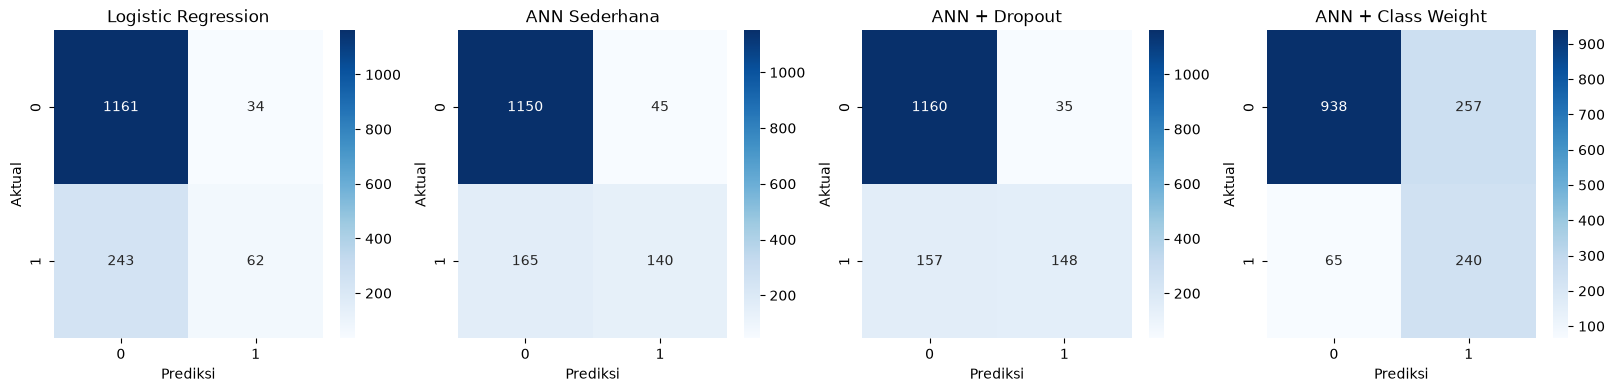

In [22]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, (name, (p, _)) in zip(ax, preds.items()):
    sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt='d', cmap='Blues', ax=a)
    a.set_title(name)
    a.set_xlabel('Prediksi')
    a.set_ylabel('Aktual')
plt.show()

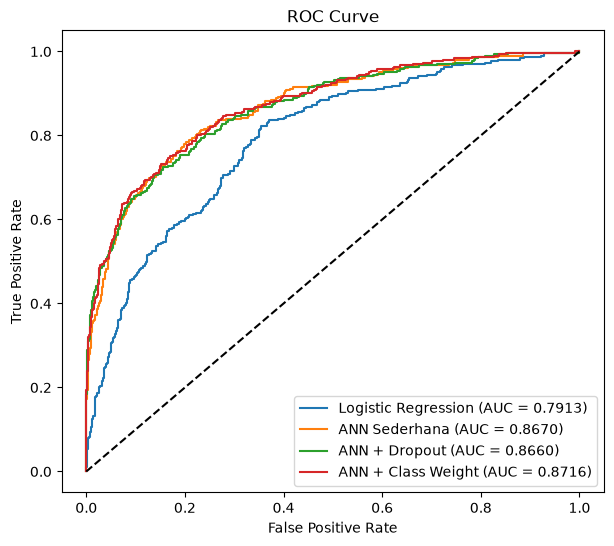

In [23]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.
plt.figure(figsize=(7, 6))
for name, (_, prob) in preds.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, prob):.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa Logistic Regression dan setiap konfigurasi ANN berdasarkan hasil evaluasi. Bahas pula bentuk learning curve masing-masing model (overfitting/underfitting), pengaruh penambahan layer dan Dropout, serta pengaruh class weight terhadap precision dan recall kelas churn. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

**Hasil evaluasi pada test set:**

| Model | Accuracy | Precision | Recall | F1-Score | AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.8153 | 0.6458 | 0.2033 | 0.3092 | 0.7913 |
| ANN Sederhana | 0.8600 | 0.7568 | 0.4590 | 0.5714 | 0.8670 |
| ANN + Dropout | 0.8720 | 0.8087 | 0.4852 | 0.6066 | 0.8660 |
| ANN + Class Weight | 0.7853 | 0.4829 | 0.7869 | 0.5985 | 0.8716 |

1. **Logistic Regression vs ANN.** Logistic Regression hanya mencapai accuracy 0.8153, sedikit di atas tebakan kelas mayoritas (79.6% nasabah tidak churn). Recall churn-nya juga sangat rendah (0.2033): hanya 62 dari 305 nasabah churn yang terdeteksi. Seluruh ANN jauh lebih baik (AUC sekitar 0.87 vs 0.79), karena hubungan fitur dengan churn tidak linear. Contohnya dari EDA, proporsi churn turun dari 1 ke 2 produk lalu melonjak tajam pada 3–4 produk, dan churn paling banyak pada usia sekitar 40–60 tahun. Hidden layer dengan aktivasi ReLU dapat menangkap pola seperti ini, sedangkan model linear tidak.

2. **Learning curve.** Pada ANN sederhana, loss train dan validation turun bersama lalu mendatar setelah sekitar epoch 20 (±0.34 / 0.33). Accuracy train dan validation juga berimpit di ±0.86, sehingga tidak ada tanda overfitting maupun underfitting. Pada ANN + Dropout, loss dan accuracy validation selalu sedikit lebih baik dari train. Hal ini wajar karena Dropout hanya aktif saat training, sedangkan saat validasi seluruh neuron dipakai. Val loss terus turun sampai ±0.32 dan tidak naik kembali, sehingga model ini juga tidak overfitting.

3. **Pengaruh penambahan layer dan Dropout.** Model yang lebih dalam (2 hidden layer, 2.945 parameter vs 225) dengan Dropout 0.3 meningkatkan hampir semua metrik:
   - accuracy 0.8600 → 0.8720
   - precision 0.7568 → 0.8087
   - recall 0.4590 → 0.4852
   - F1 0.5714 → 0.6066

   AUC-nya hampir sama (0.8670 vs 0.8660). Artinya kapasitas tambahan membantu model menentukan batas keputusan pada threshold 0.5 dengan lebih baik, sedangkan kemampuan model untuk mengurutkan probabilitas tidak banyak berubah. Dropout menjaga model yang lebih besar ini tetap tidak overfitting.

4. **Pengaruh class weight.** `compute_class_weight("balanced")` memberi bobot 0.628 untuk kelas 0 dan 2.454 untuk kelas 1, sehingga kesalahan pada nasabah churn ±3.9 kali lebih mahal. Recall churn naik drastis (0.4852 → 0.7869): nasabah churn yang terdeteksi naik dari 148 menjadi 240 dari 305. Sebagai gantinya, false positive naik dari 35 menjadi 257, sehingga precision turun (0.8087 → 0.4829) dan accuracy turun ke 0.7853. Learning curve-nya lebih fluktuatif dan nilai loss-nya lebih besar karena dihitung dengan bobot. AUC-nya justru yang tertinggi (0.8716). Jadi class weight tidak merusak kemampuan model membedakan kelas, tetapi menggeser keputusan ke arah kelas churn.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

1. Data churn bersifat imbalanced (±20% churn), sehingga accuracy saja menyesatkan. Precision, recall, F1, dan AUC perlu ikut diperhatikan.
2. Semua konfigurasi ANN mengungguli baseline Logistic Regression secara signifikan (F1 ±0.57–0.61 vs 0.31, AUC ±0.87 vs 0.79), sehingga penggunaan ANN layak.
3. ANN + Dropout memberi accuracy (0.8720), precision (0.8087), dan F1 (0.6066) tertinggi. ANN + Class Weight memberi recall tertinggi (0.7869) dan AUC tertinggi (0.8716), lebih cocok untuk bank yang ingin menangkap sebanyak mungkin nasabah yang berpotensi churn untuk program retensi.
4. Tidak ada model yang overfitting. Kurva train dan validation tetap berdekatan sampai epoch 50.

**Saran:**
- Mengatur threshold keputusan (selain 0.5) berdasarkan precision-recall curve agar keseimbangan precision dan recall sesuai kebutuhan bisnis.
- Menambahkan `EarlyStopping` berdasarkan `val_loss` dan melakukan tuning hyperparameter (jumlah neuron, dropout rate, learning rate).
- Mencoba feature engineering (misalnya flag `Balance == 0` atau kelompok usia) serta membandingkan dengan model tree-based seperti Random Forest/XGBoost.
- Menggunakan cross-validation agar hasil evaluasi lebih stabil.